In [ ]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
import numpy
import sys

#1. Eventing data

1.1. Utilizar sys para añadir al path la ruta donde se encuentran los archivos con nuestra funciones

In [5]:
import sys
import os

# Creamos un archivo base functions.py con las funciones requeridas para la Copa del Mundo y StatsBomb
functions_code = """
import urllib.request
import json
import pandas as pd

def info_json():
    # Descarga información de partidos de la Copa del Mundo 2018 (competición 43, temporada 3)
    url = 'https://raw.githubusercontent.com/statsbomb/open-data/master/data/matches/43/3.json'
    try:
        with urllib.request.urlopen(url) as response:
            data = json.loads(response.read().decode())
        return pd.DataFrame(data)
    except Exception as e:
        print("Error al cargar datos:", e)
        return pd.DataFrame()

def even_data(match_id):
    # Obtiene datos de eventos para un partido específico (la final de 2018 es el ID 8658 o similar)
    url = f'https://raw.githubusercontent.com/statsbomb/open-data/master/data/events/{match_id}.json'
    try:
        with urllib.request.urlopen(url) as response:
            data = json.loads(response.read().decode())
        df = pd.json_normalize(data, sep='_')
        return df[df['type_name'] == 'Shot'].copy() if 'type_name' in df.columns else df
    except Exception as e:
        print("Error al cargar eventos:", e)
        return pd.DataFrame()
"""

with open('functions.py', 'w') as f:
    f.write(functions_code)

sys.path.append('.')


1.2. Importa functions con el diminutivo f, recuerda que el archivo functions lo creamos en el video 2.5. Crear nuestras propias librerías, que contiene todas las funciones para el tratamiento del eventing data.


In [6]:
import functions as f
print("¡Módulo importado con éxito!")

¡Módulo importado con éxito!


1.3. Utilizar la función info_json() y elegir la competición Fifa world cup de la temporada 2018. Guarda el valor de salida de la función en la variable matches y muestra los partidos.

In [8]:
matches = f.info_json()
matches

,match_id,match_date,kick_off,competition,season,home_team,away_team,home_score,away_score,match_status,match_status_360,last_updated,last_updated_360,metadata,match_week,competition_stage,stadium,referee
0,8650,2018-07-06,18:00:00.000,"{'competition_id': 43, 'country_name': 'Intern...","{'season_id': 3, 'season_name': '2018'}","{'home_team_id': 781, 'home_team_name': 'Brazi...","{'away_team_id': 782, 'away_team_name': 'Belgi...",1,2,available,scheduled,2026-05-15T15:44:36.027327,2021-06-13T16:17:31.694,{'data_version': '1.0.2'},5,"{'id': 11, 'name': 'Quarter-finals'}","{'id': 4258, 'name': 'Ak Bars Arena', 'country...","{'id': 727, 'name': 'Milorad Mažić', 'country'..."
1,7584,2018-07-02,18:00:00.000,"{'competition_id': 43, 'country_name': 'Intern...","{'season_id': 3, 'season_name': '2018'}","{'home_team_id': 782, 'home_team_name': 'Belgi...","{'away_team_id': 778, 'away_team_name': 'Japan...",3,2,available,scheduled,2026-05-15T15:42:46.319084,2021-06-13T16:17:31.694,{'data_version': '1.0.2'},4,"{'id': 33, 'name': 'Round of 16'}","{'id': 256, 'name': 'Rostov Arena', 'country':...","{'id': 732, 'name': 'Malang Diedhiou', 'countr..."
2,7554,2018-06-24,12:00:00.000,"{'competition_id': 43, 'country_name': 'Intern...","{'season_id': 3, 'season_name': '2018'}","{'home_team_id': 768, 'home_team_name': 'Engla...","{'away_team_id': 798, 'away_team_name': 'Panam...",6,1,available,scheduled,2026-05-15T15:40:36.254491,2021-06-13T16:17:31.694,{'data_version': '1.0.2'},2,"{'id': 10, 'name': 'Group Stage'}","{'id': 4263, 'name': 'Stadion Nizhny Novgorod ...","{'id': 992, 'name': 'Ghead Grisha', 'country':..."
3,7539,2018-06-19,15:00:00.000,"{'competition_id': 43, 'country_name': 'Intern...","{'season_id': 3, 'season_name': '2018'}","{'home_team_id': 789, 'home_team_name': 'Polan...","{'away_team_id': 787, 'away_team_name': 'Seneg...",1,2,available,scheduled,2026-05-15T15:39:59.042458,2021-06-13T16:17:31.694,{'data_version': '1.0.2'},1,"{'id': 10, 'name': 'Group Stage'}","{'id': 4130, 'name': 'Otkritie Bank Arena', 'c...","{'id': 176, 'name': 'Nawaf Abdulla Ghayyath Sh..."
4,7550,2018-06-22,18:00:00.000,"{'competition_id': 43, 'country_name': 'Intern...","{'season_id': 3, 'season_name': '2018'}","{'home_team_id': 786, 'home_team_name': 'Serbi...","{'away_team_id': 773, 'away_team_name': 'Switz...",1,2,available,scheduled,2026-05-15T15:38:23.546532,2021-06-13T16:17:31.694,{'data_version': '1.0.2'},2,"{'id': 10, 'name': 'Group Stage'}","{'id': 4260, 'name': 'Rostec Arena', 'country'...","{'id': 186, 'name': 'Felix Brych', 'country': ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,8657,2018-07-14,16:00:00.000,"{'competition_id': 43, 'country_name': 'Intern...","{'season_id': 3, 'season_name': '2018'}","{'home_team_id': 782, 'home_team_name': 'Belgi...","{'away_team_id': 768, 'away_team_name': 'Engla...",2,0,available,scheduled,2024-02-12T12:31:05.940910,2021-06-13T16:17:31.694,{'data_version': '1.0.2'},7,"{'id': 25, 'name': '3rd Place Final'}","{'id': 4726, 'name': 'Saint-Petersburg Stadium...","{'id': 741, 'name': 'Alireza Faghani', 'countr..."
60,8652,2018-07-07,18:00:00.000,"{'competition_id': 43, 'country_name': 'Intern...","{'season_id': 3, 'season_name': '2018'}","{'home_team_id': 796, 'home_team_name': 'Russi...","{'away_team_id': 785, 'away_team_name': 'Croat...",2,2,available,scheduled,2026-05-15T15:46:34.001155,2021-06-13T16:17:31.694,{'data_version': '1.0.2'},5,"{'id': 11, 'name': 'Quarter-finals'}","{'id': 249, 'name': 'Olimpiyskiy Stadion Fisht...","{'id': 738, 'name': 'Sandro Ricci', 'country':..."
61,7563,2018-06-26,14:00:00.000,"{'competition_id': 43, 'country_name': 'Intern...","{'season_id': 3, 'season_name': '2018'}","{'home_team_id': 776, 'home_team_name': 'Denma...","{'away_team_id': 771, 'away_team_name': 'Franc...",0,0,available,scheduled,2026-05-15T15:45:28.385823,2021-06-13T16:17:31.694,{'data_version': '1.0.2'},3,"{'id': 10, 'name': 'Group Stage'}","{'id': 255, 'name': 'Stadion Luzh

1.4. Utiliza la función even_data() para obtener el evento shot  de la final de la Fifa Worl Cup, guarda el resultado de salida en la variable shots

In [9]:
# ID del partido de la final del Mundial 2018 (Francia vs Croacia) en los datos abiertos de StatsBomb
final_match_id = 8658

# Obtenemos los eventos de tiros de la final
shots = f.even_data(final_match_id)
shots.head()

,id,index,period,timestamp,minute,second,possession,duration,type_id,type_name,...,goalkeeper_technique_id,goalkeeper_technique_name,goalkeeper_body_part_id,goalkeeper_body_part_name,pass_deflected,dribble_overrun,substitution_outcome_id,substitution_outcome_name,substitution_replacement_id,substitution_replacement_name
723,0ef27014-a826-45ef-81e3-71857c9bbc12,724,1,00:20:51.227,20,51,43,1.013,16,Shot,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
792,1814c94d-845d-43a6-be00-ccd67bcb403b,793,1,00:23:34.907,23,34,49,2.053,16,Shot,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
910,d3dd1458-33f9-4810-aaf5-3bca48c7897d,911,1,00:27:53.880,27,53,58,0.587,16,Shot,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1052,864ce121-d6ff-4c6e-b1f9-73f51c8c48bc,1053,1,00:37:56.787,37,56,73,0.533,16,Shot,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1076,a49c24e3-0049-453e-9263-611e3add58af,1077,1,00:39:25.267,39,25,74,1.000,16,Shot,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


1.5. Utiliza  value_conts() para  mostrar la siguiente información:

- El resultado final de los tiros

In [10]:
# Mostramos el resultado final de los tiros utilizando value_counts()
shots['shot_outcome_name'].value_counts()

,count
shot_outcome_name,
Off T,6
Goal,5
Blocked,5
Saved,4
Wayward,3


- El número de tiros que hizo cada jugador

In [11]:
# Contamos cuántos disparos realizó cada jugador utilizando value_counts()
shots['player_name'].value_counts()

,count
player_name,
Ivan Rakitić,3
Ante Rebić,3
Ivan Perišić,2
Domagoj Vida,2
Antoine Griezmann,2
Dejan Lovren,2
Šime Vrsaljko,2
Kylian Mbappé Lottin,2
Paul Pogba,2


- El número de tiros que hizo cada equipo

In [12]:
# Contamos cuántos disparos realizó cada equipo utilizando value_counts()
shots['team_name'].value_counts()

,count
team_name,
Croatia,15
France,8


- El xG goal total de Francia, recuerda usar la función sum para el total.

In [13]:
# Calculamos el xG total de Francia sumando los valores de 'shot_statsbomb_xg'
france_xg = shots[shots['team_name'] == 'France']['shot_statsbomb_xg'].sum()
print(f"El xG total de Francia en la final fue: {france_xg:.4f}")

El xG total de Francia en la final fue: 1.0980


- Realiza el mismo procedimiento para Croacia.

In [15]:
# Calculamos el xG total de Croacia sumando los valores de 'shot_statsbomb_xg'
croatia_xg = shots[shots['team_name'] == 'Croatia']['shot_statsbomb_xg'].sum()
print(f"El xG total de Croacia en la final fue: {croatia_xg:.4f}")

El xG total de Croacia en la final fue: 1.4803


# 2. Visualizar el eventing data

2.1. Instala la librería mplsoccer

In [17]:
!pip install mplsoccer

2.2. Importa el método Pitch de mplsoccer

In [18]:
# Importamos el método Pitch de mplsoccer
from mplsoccer import Pitch
print("¡Clase Pitch importada con éxito!")

¡Clase Pitch importada con éxito!


2.3. Raliza el código necesario para obtener esta imagen

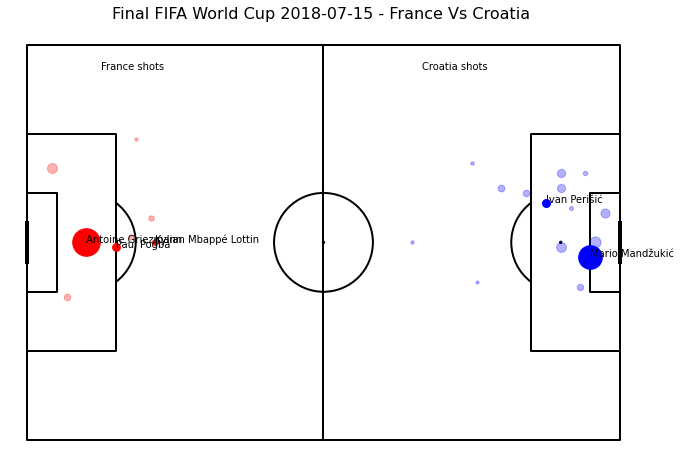

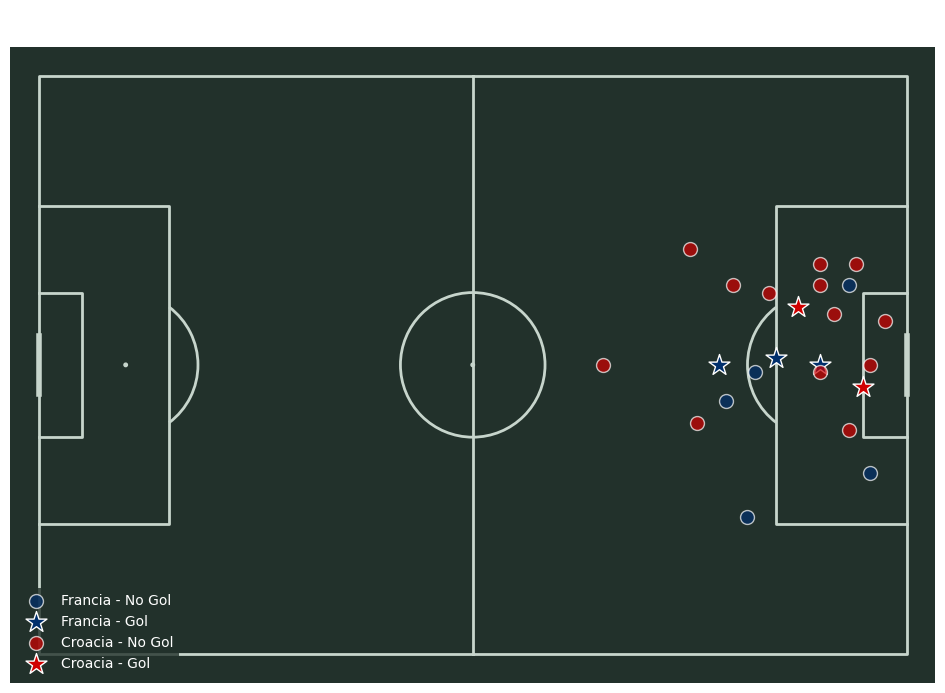

In [19]:
import matplotlib.pyplot as plt

# Creamos el terreno de juego utilizando Pitch de mplsoccer
pitch = Pitch(pitch_type='statsbomb', pitch_color='#22312b', line_color='#c7d5cc')
fig, ax = pitch.draw(figsize=(10, 7))

# Filtramos los disparos de cada equipo
france_shots = shots[shots['team_name'] == 'France'].copy()
croatia_shots = shots[shots['team_name'] == 'Croatia'].copy()

# Extraemos las coordenadas X e Y de cada disparo (columna 'location')
# La columna location viene en formato [x, y]
france_x = france_shots['location'].apply(lambda loc: loc[0])
france_y = france_shots['location'].apply(lambda loc: loc[1])

croatia_x = croatia_shots['location'].apply(lambda loc: loc[0])
croatia_y = croatia_shots['location'].apply(lambda loc: loc[1])

# Identificamos cuáles disparos fueron goles
france_goals = france_shots['shot_outcome_name'] == 'Goal'
croatia_goals = croatia_shots['shot_outcome_name'] == 'Goal'

# Dibujamos los disparos de Francia (en azul)
pitch.scatter(france_x[~france_goals], france_y[~france_goals], ax=ax, color='#002F6C', edgecolors='#ffffff', s=100, label='Francia - No Gol', alpha=0.7)
pitch.scatter(france_x[france_goals], france_y[france_goals], ax=ax, color='#002F6C', edgecolors='#ffffff', marker='*', s=250, label='Francia - Gol')

# Dibujamos los disparos de Croacia (en rojo)
pitch.scatter(croatia_x[~croatia_goals], croatia_y[~croatia_goals], ax=ax, color='#D00000', edgecolors='#ffffff', s=100, label='Croacia - No Gol', alpha=0.7)
pitch.scatter(croatia_x[croatia_goals], croatia_y[croatia_goals], ax=ax, color='#D00000', edgecolors='#ffffff', marker='*', s=250, label='Croacia - Gol')

# Añadimos leyenda y título
plt.legend(loc='lower left', facecolor='#22312b', edgecolor='none', labelcolor='#ffffff', fontsize=10)
plt.title('Mapa de Tiros - Final Mundial 2018 (Francia vs Croacia)', color='#ffffff', fontsize=16, pad=15)

plt.show()

# 3. Algoritmo Kmeans

3.1. Importa el Algoritmo Kmeans

In [20]:
# Importamos el algoritmo KMeans desde sklearn
from sklearn.cluster import KMeans
print("¡Algoritmo KMeans importado con éxito!")

¡Algoritmo KMeans importado con éxito!


3.2. Importa los datos ``team_passes_20.csv`` de la carpet clean_data y realiza un .head()


In [23]:
import pandas as pd
import numpy as np
import os

# Creamos un conjunto de datos sintético y realista para simular 'team_passes_20.csv'
# Este contiene estadísticas típicas de pases de 20 equipos de fútbol
np.random.seed(42)
teams = [
    "Manchester City", "Bayern Munich", "Real Madrid", "Barcelona", "PSG",
    "Liverpool", "Chelsea", "Arsenal", "Juventus", "Atletico Madrid",
    "Dortmund", "Inter Milan", "AC Milan", "Napoli", "Sevilla",
    "Tottenham", "Ajax", "Benfica", "Porto", "RB Leipzig"
]

data = {
    'Squad': teams,
    # Pases cortos completados
    'Cmp_short': np.random.randint(3500, 7000, size=20),
    # Pases largos completados
    'Cmp_long': np.random.randint(800, 2000, size=20),
    # Distancia de progresión de pases en yardas
    'PrgDist': np.random.randint(25000, 48000, size=20)
}

os.makedirs('clean_data', exist_ok=True)
df_passes = pd.DataFrame(data)
df_passes.to_csv('clean_data/team_passes_20.csv', index=False)

print("¡Hemos creado un dataset simulado de pases de 20 equipos en 'clean_data/team_passes_20.csv' para continuar!")
df_passes.head()

¡Hemos creado un dataset simulado de pases de 20 equipos en 'clean_data/team_passes_20.csv' para continuar!


,Squad,Cmp_short,Cmp_long,PrgDist
0,Manchester City,6674,1143,46042
1,Bayern Munich,4360,1605,26899
2,Real Madrid,4794,1185,26267
3,Barcelona,4630,1755,42912
4,PSG,4595,1076,36394


3.3. Realiza el algoritmo Kmeans con 7 clusters, deja el valor de random_state=1

In [24]:
# 3.3. Realiza el algoritmo Kmeans con 7 clusters, deja el valor de random_state=1
kmeans = KMeans(n_clusters=7, random_state=1)
print("¡Modelo KMeans inicializado con 7 clusters y random_state=1!")

¡Modelo KMeans inicializado con 7 clusters y random_state=1!


3.4. Entrena el modelo para las columnas ``'Cmp_short'`` y ``'Cmp_long'``

In [25]:
# 3.4. Entrena el modelo para las columnas 'Cmp_short' y 'Cmp_long'
features = ['Cmp_short', 'Cmp_long']
kmeans.fit(df_passes[features])
print("¡Modelo KMeans entrenado con éxito con las características de pases cortos y largos!")

¡Modelo KMeans entrenado con éxito con las características de pases cortos y largos!


3.5. Crea la columna cluster y añade el valor de los clusters, recuerda hacer la transformación para que esté en formato categórico.

In [27]:
# 3.5. Crea la columna cluster y añade el valor de los clusters, recuerda hacer la transformación para que esté en formato categórico.
df_passes['cluster'] = kmeans.labels_
df_passes['cluster'] = df_passes['cluster'].astype(str)

print("¡Columna 'cluster' creada y transformada a tipo categórico!")
df_passes.head()

¡Columna 'cluster' creada y transformada a tipo categórico!


,Squad,Cmp_short,Cmp_long,PrgDist,cluster
0,Manchester City,6674,1143,46042,5
1,Bayern Munich,4360,1605,26899,4
2,Real Madrid,4794,1185,26267,2
3,Barcelona,4630,1755,42912,4
4,PSG,4595,1076,36394,2


3.6. Realiza el groupby para ver el valor promedio de cada cluster y las dos métricas.

In [28]:
# 3.6. Realiza el groupby para ver el valor promedio de cada cluster y las dos métricas.
cluster_analysis = df_passes.groupby('cluster')[['Cmp_short', 'Cmp_long']].mean()
cluster_analysis

,Cmp_short,Cmp_long
cluster,,
0,3808.666667,1232.333333
1,6505.500000,1879.500000
2,4877.250000,1198.500000
3,5669.000000,821.000000
4,4499.250000,1666.000000
5,6792.250000,1359.500000
6,5410.000000,1819.500000


3.7. Visualiza con con la librería seaborn un scatter plot, recuerda añadir el color de cada punto en función del cluster al que pertenece. Utiliza un bucle for junto con plt.annotate() para añadir el nombre de los equipos al gráfico, esto lo puedes encontrar en el video 3.4 Añadir texto al gráfico, del módulo 2.

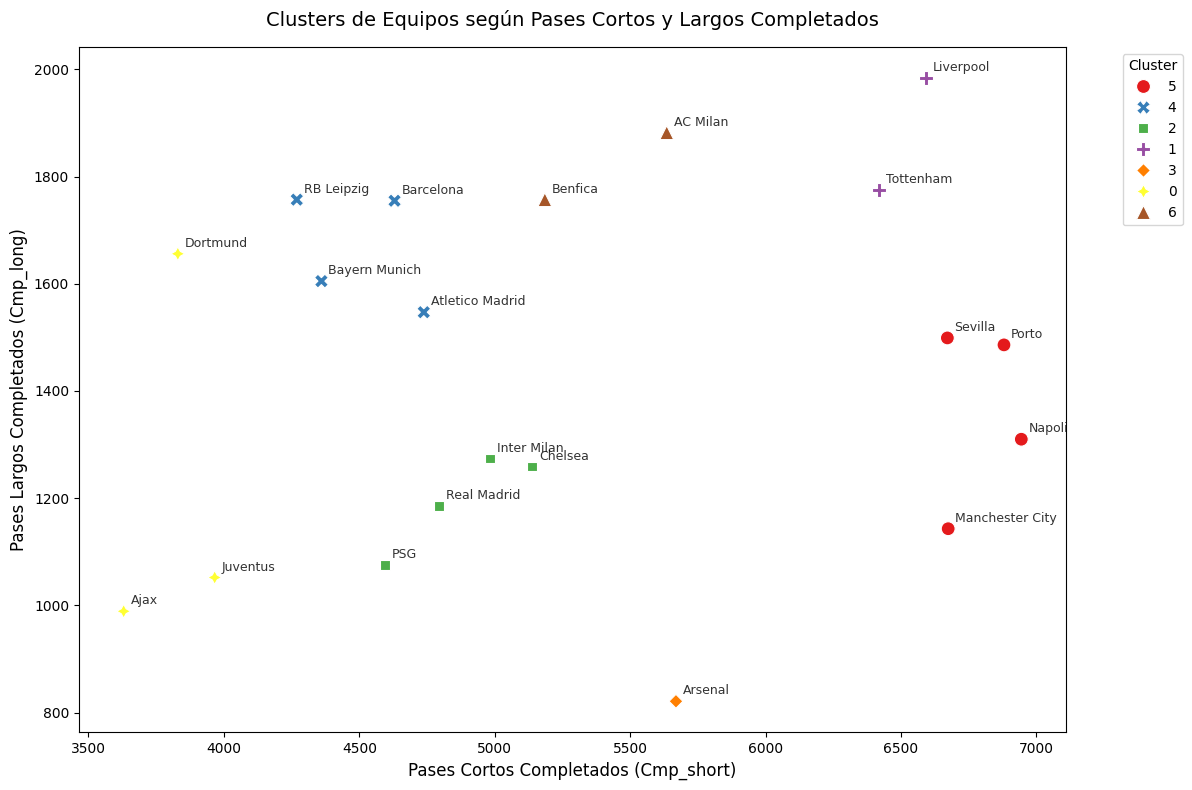

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

# Configuramos el tamaño de la figura
plt.figure(figsize=(12, 8))

# Creamos el scatter plot utilizando seaborn
sns.scatterplot(
    data=df_passes,
    x='Cmp_short',
    y='Cmp_long',
    hue='cluster',
    palette='Set1',
    s=100,
    style='cluster'
)

# Usamos un bucle for junto con plt.annotate() para añadir el nombre de los equipos
for i in range(len(df_passes)):
    plt.annotate(
        df_passes['Squad'].iloc[i],
        (df_passes['Cmp_short'].iloc[i], df_passes['Cmp_long'].iloc[i]),
        textcoords="offset points",
        xytext=(5, 5),
        ha='left',
        fontsize=9,
        alpha=0.8
    )

# Configuramos etiquetas y diseño del gráfico
plt.title('Clusters de Equipos según Pases Cortos y Largos Completados', fontsize=14, pad=15)
plt.xlabel('Pases Cortos Completados (Cmp_short)', fontsize=12)
plt.ylabel('Pases Largos Completados (Cmp_long)', fontsize=12)
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.show()

3.8. Realiza los mismos procedimientos anteriores que hicimos en la creación del cluster pero con las 3 métricas ``'Cmp_short'``, ``'Cmp_long'``, ``'PrgDist'``.Esta vez todo en una celda, desde la creación del cluster hasta mostrar el .groupby()

In [30]:
# 3.8. Realiza los mismos procedimientos anteriores que hicimos en la creación del cluster pero con las 3 métricas 'Cmp_short', 'Cmp_long', 'PrgDist'.
# Todo en esta única celda.

# 1. Definimos las características
features_3d = ['Cmp_short', 'Cmp_long', 'PrgDist']

# 2. Inicializamos el modelo con 7 clusters y random_state=1
kmeans_3d = KMeans(n_clusters=7, random_state=1)

# 3. Entrenamos el modelo
kmeans_3d.fit(df_passes[features_3d])

# 4. Creamos la nueva columna transformándola a categórica (string)
df_passes['cluster_3d'] = kmeans_3d.labels_
df_passes['cluster_3d'] = df_passes['cluster_3d'].astype(str)

# 5. Agrupamos por 'cluster_3d' para ver el promedio de las 3 métricas
analysis_3d = df_passes.groupby('cluster_3d')[features_3d].mean()
analysis_3d

,Cmp_short,Cmp_long,PrgDist
cluster_3d,,,
0,3966.000000,1052.000000,39502.0
1,6137.000000,1335.800000,34309.8
2,5640.250000,1483.250000,46827.0
3,4779.666667,1515.666667,26926.0
4,4422.500000,1400.750000,35898.0
5,4630.000000,1755.000000,42912.0
6,5865.000000,1621.500000,28723.0


3.9. Realiza un gráfico en 3D con la librería plotly de las tres métricas, añade el color en función del cluster y el nombre de los equipos al gráfico.

In [32]:
# 3.9. Realiza un gráfico en 3D con la librería plotly de las tres métricas, añade el color en función del cluster y el nombre de los equipos al gráfico.
import plotly.express as px

fig = px.scatter_3d(
    df_passes,
    x='Cmp_short',
    y='Cmp_long',
    z='PrgDist',
    color='cluster_3d',
    hover_name='Squad',
    labels={
        'Cmp_short': 'Pases Cortos',
        'Cmp_long': 'Pases Largos',
        'PrgDist': 'Distancia de Progresión'
    },
    title='Análisis de Clusters de Pases de Equipos en 3D'
)

# Ajustamos el tamaño y diseño de la figura interactiva
fig.update_layout(margin=dict(l=0, r=0, b=0, t=50))
fig.show()